# CNN Image Classification — Fashion-MNIST
**Group project: Jaringan Syaraf Tiruan (Convolutional Neural Network)**

This notebook builds a complete CNN pipeline in Python (TensorFlow/Keras), split into 5 parts — one per group member:

| Part | Topic | Owner |
|---|---|---|
| 1 | Data & preprocessing | Member 1 |
| 2 | CNN theory & visualization (convolution, ReLU, pooling) | Member 2 |
| 3 | Model architecture (comparing 3 CNNs) | Member 3 |
| 4 | Training & tuning | Member 4 |
| 5 | Evaluation, error analysis & demo | Member 5 |

Run it top to bottom (`Runtime → Run all` in Google Colab). A GPU runtime is faster but not required.

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix
import time

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices('GPU')) > 0)

I0000 00:00:1795519654.489193     362 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795519654.672027     362 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795519660.494902     362 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0
GPU available: False


---
# PART 1 — Data & Preprocessing (Member 1)
Fashion-MNIST has **70,000 grayscale images (28×28 px)** of clothing in **10 classes**: 60,000 for training and 10,000 for testing.

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print("Train images:", x_train_full.shape, "| Train labels:", y_train_full.shape)
print("Test images :", x_test.shape,       "| Test labels :", y_test.shape)
print("Pixel range :", x_train_full.min(), "to", x_train_full.max(), "| dtype:", x_train_full.dtype)

Train images: (60000, 28, 28) | Train labels: (60000,)
Test images : (10000, 28, 28) | Test labels : (10000,)
Pixel range : 0 to 255 | dtype: uint8


### 1.1 Sample images

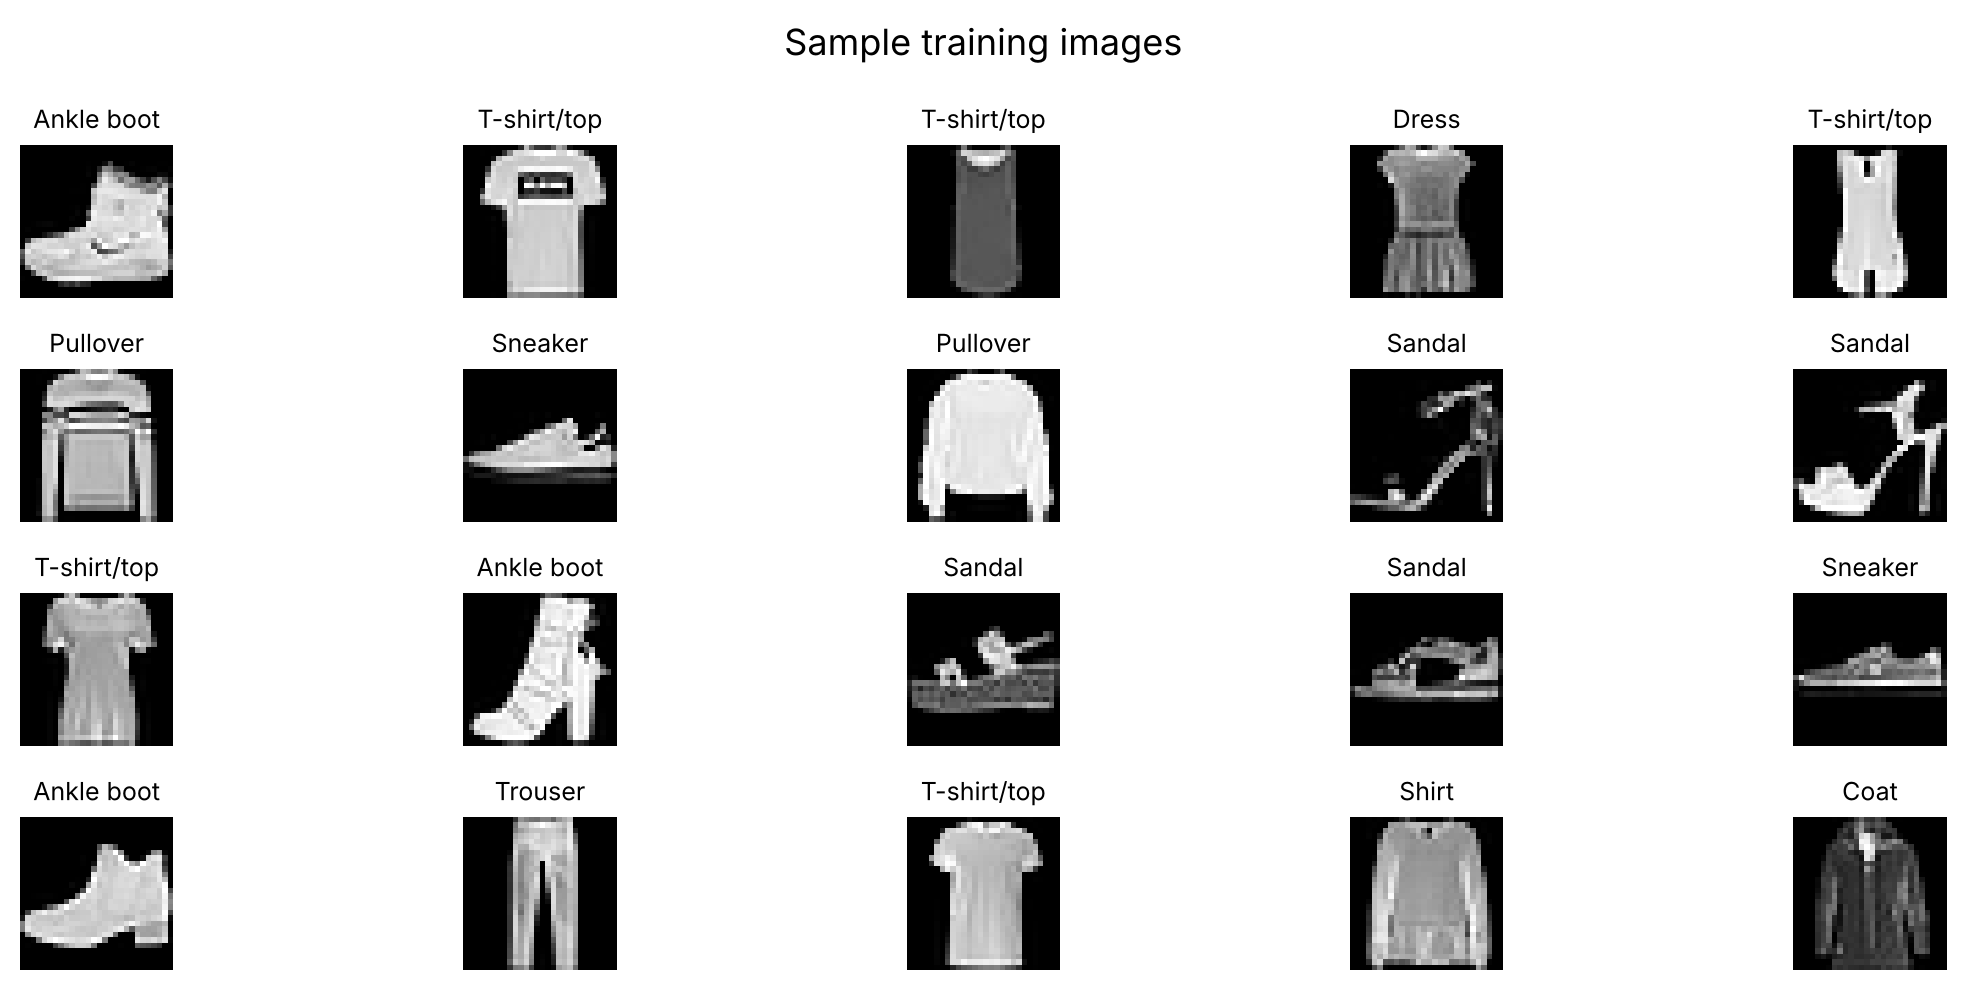

In [3]:
plt.figure(figsize=(12, 5))
for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(x_train_full[i], cmap='gray')
    plt.title(class_names[y_train_full[i]], fontsize=9)
    plt.axis('off')
plt.suptitle("Sample training images", fontsize=13)
plt.tight_layout()
plt.show()

### 1.2 Class distribution
A balanced dataset means accuracy is a fair metric (no class dominates).

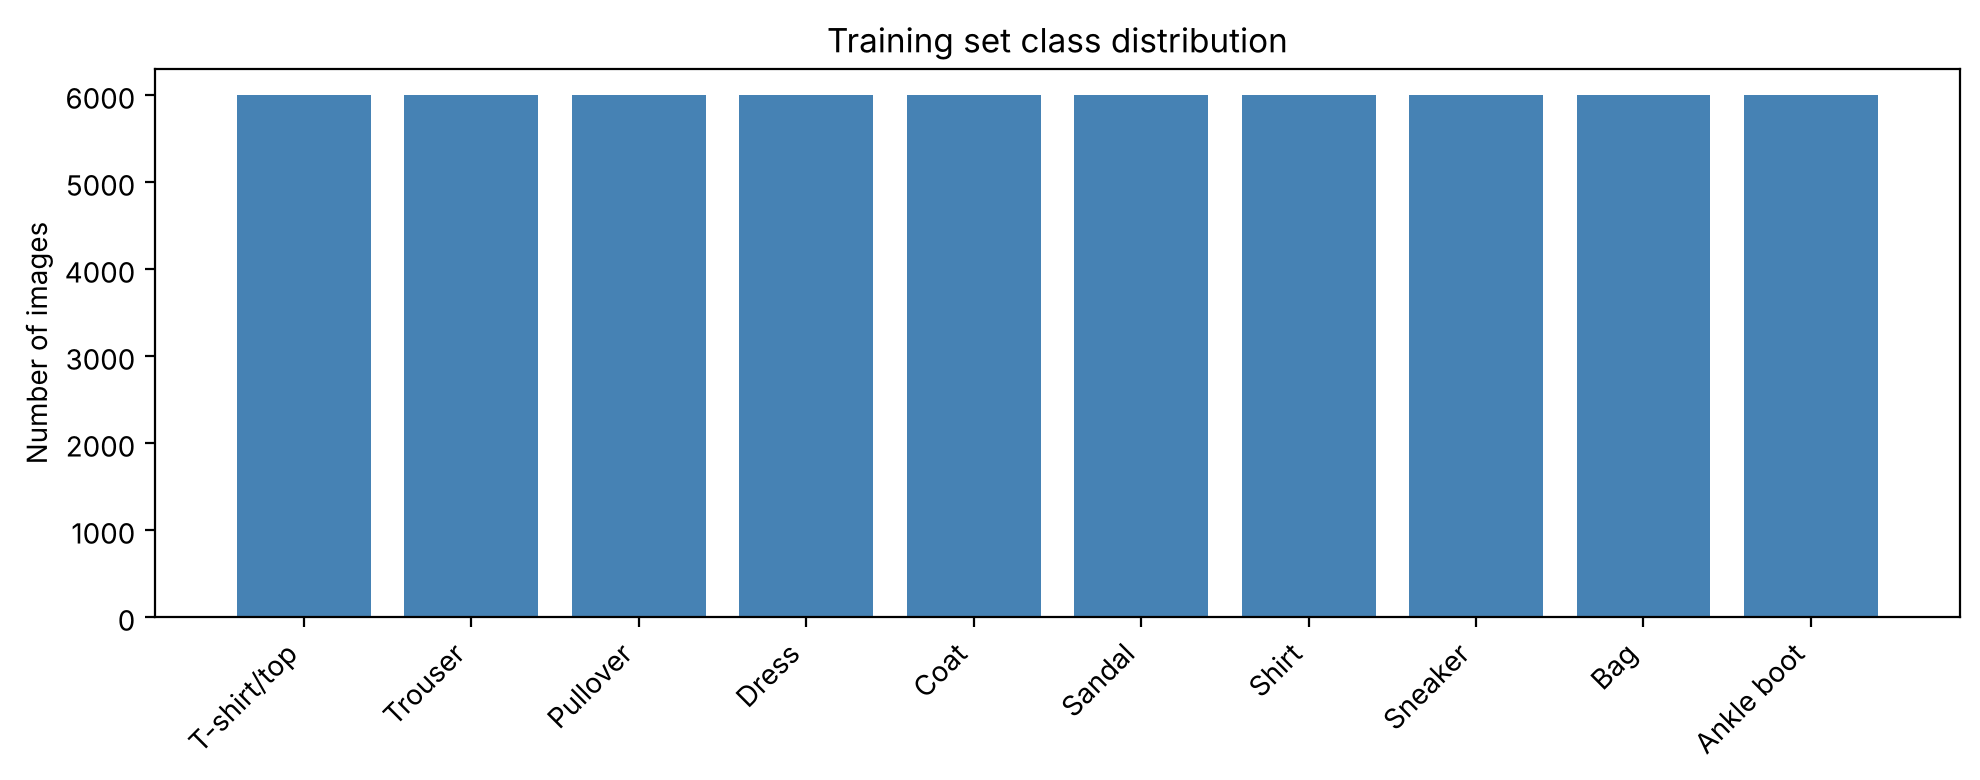

T-shirt/top : 6000
Trouser     : 6000
Pullover    : 6000
Dress       : 6000
Coat        : 6000
Sandal      : 6000
Shirt       : 6000
Sneaker     : 6000
Bag         : 6000
Ankle boot  : 6000


In [4]:
counts = np.bincount(y_train_full)
plt.figure(figsize=(10, 4))
plt.bar(class_names, counts, color='steelblue')
plt.xticks(rotation=45, ha='right')
plt.ylabel("Number of images")
plt.title("Training set class distribution")
plt.tight_layout()
plt.show()
for name, c in zip(class_names, counts):
    print(f"{name:12s}: {c}")

### 1.3 Preprocessing
1. **Normalize** pixels from 0–255 to 0–1 → training is more stable and faster.
2. **Reshape** to (28, 28, 1) → a CNN expects a channel dimension (1 = grayscale, 3 = RGB).
3. **Split** 10% of training data as a **validation set** → used to monitor overfitting during training.

In [5]:
x_train_full = x_train_full.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train_full = x_train_full[..., np.newaxis]
x_test = x_test[..., np.newaxis]

# Shuffle then split 54,000 train / 6,000 validation
idx = np.random.permutation(len(x_train_full))
x_train_full, y_train_full = x_train_full[idx], y_train_full[idx]
x_val, y_val = x_train_full[:6000], y_train_full[:6000]
x_train, y_train = x_train_full[6000:], y_train_full[6000:]

print("Train     :", x_train.shape)
print("Validation:", x_val.shape)
print("Test      :", x_test.shape)
print("Pixel range after normalization:", x_train.min(), "to", x_train.max())

Train     : (54000, 28, 28, 1)
Validation: (6000, 28, 28, 1)
Test      : (10000, 28, 28, 1)
Pixel range after normalization: 0.0 to 1.0


### 1.4 Data augmentation preview (optional technique)
Augmentation creates slightly modified copies of images (shifted, rotated, zoomed) so the model sees more variety and generalizes better.

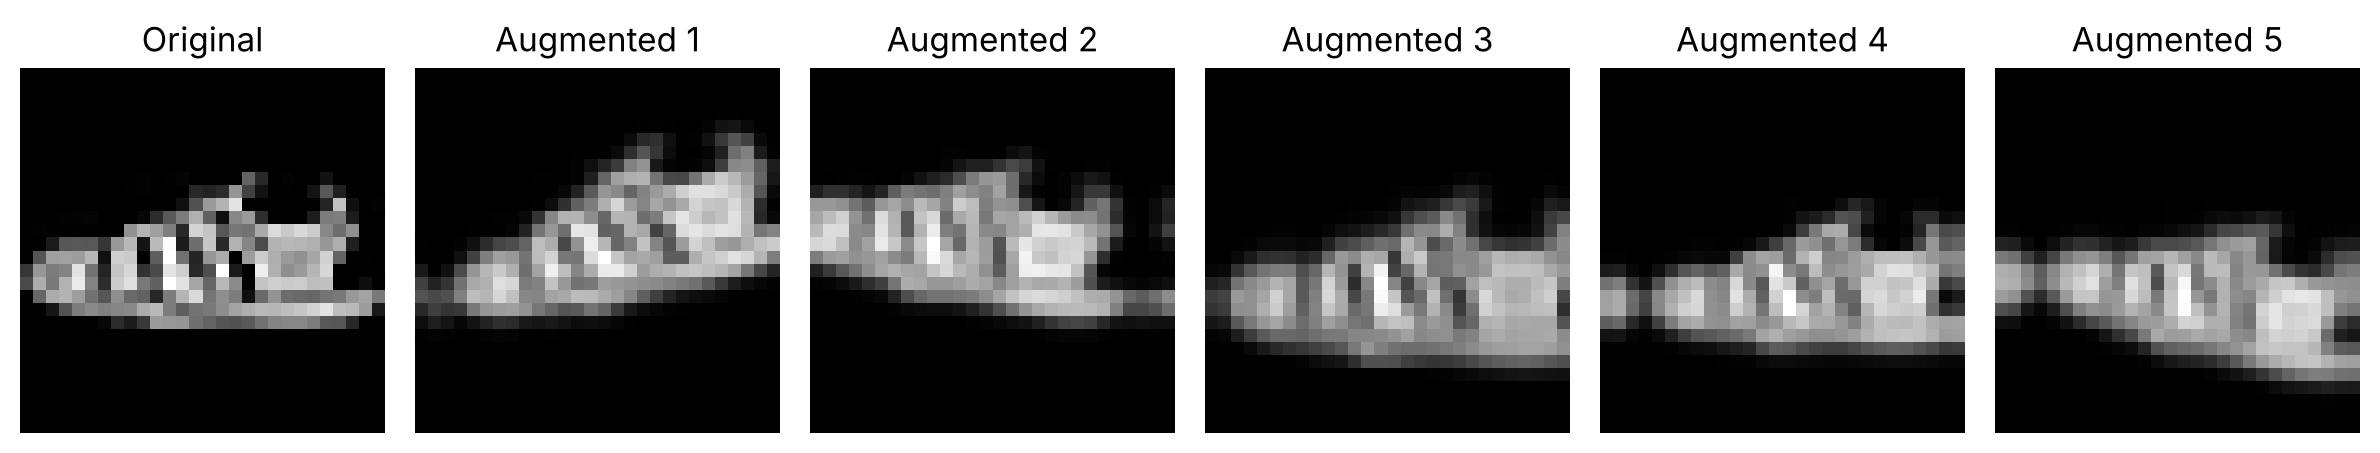

In [6]:
augment = keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom(0.1),
])

sample = x_train[:1]
plt.figure(figsize=(12, 2.5))
plt.subplot(1, 6, 1); plt.imshow(sample[0, :, :, 0], cmap='gray'); plt.title("Original"); plt.axis('off')
for i in range(5):
    aug = augment(sample, training=True)
    plt.subplot(1, 6, i + 2); plt.imshow(aug[0, :, :, 0], cmap='gray'); plt.title(f"Augmented {i+1}"); plt.axis('off')
plt.tight_layout()
plt.show()

---
# PART 2 — CNN Theory & Visualization (Member 2)
A CNN learns **filters (kernels)**: small grids of weights that slide over the image. Each position computes a weighted sum → this creates a **feature map**.

The three core operations, done manually here with NumPy:
1. **Convolution** — detect features (edges, lines)
2. **ReLU activation** — `max(0, x)`, keeps positive responses, adds non-linearity
3. **Max pooling** — downsample by keeping the strongest value in each 2×2 window

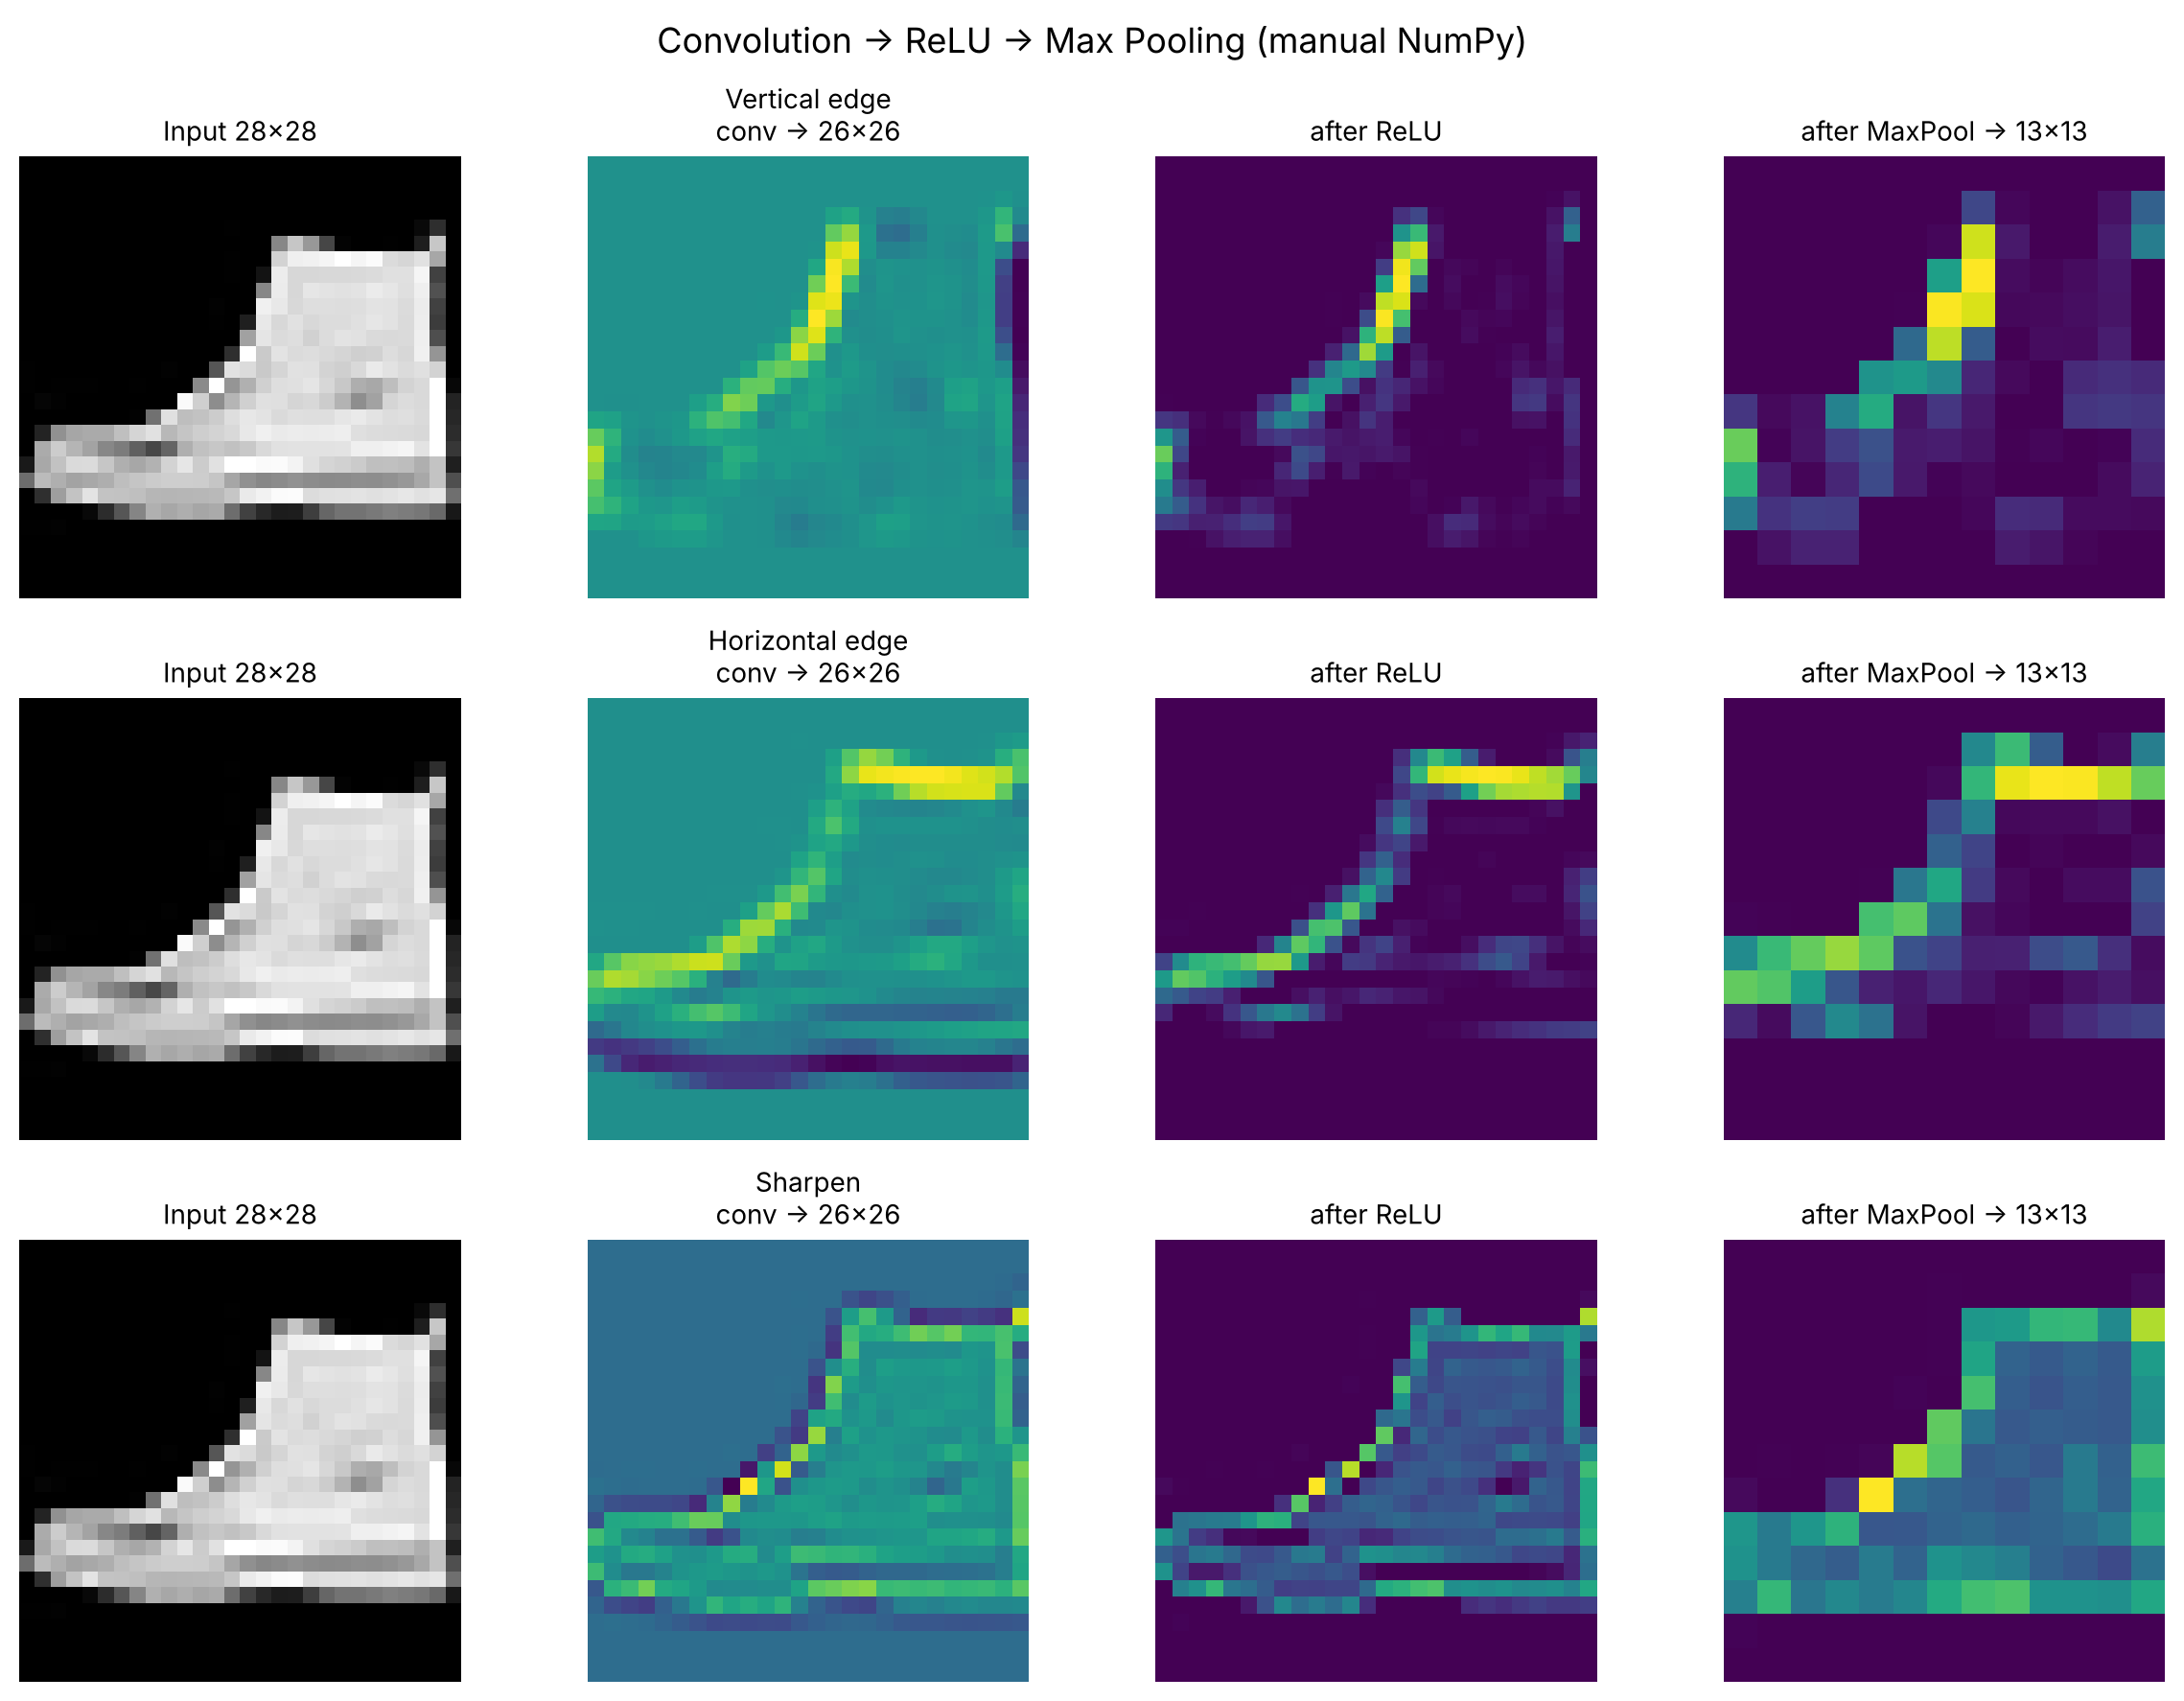

In [7]:
def convolve2d(image, kernel):
    """Manual 2D convolution (valid padding, stride 1)."""
    kh, kw = kernel.shape
    h, w = image.shape
    out = np.zeros((h - kh + 1, w - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = np.sum(image[i:i+kh, j:j+kw] * kernel)
    return out

def relu(x):
    return np.maximum(0, x)

def max_pool(x, size=2):
    h, w = x.shape[0] // size, x.shape[1] // size
    return x[:h*size, :w*size].reshape(h, size, w, size).max(axis=(1, 3))

kernels = {
    "Vertical edge":   np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    "Horizontal edge": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
    "Sharpen":         np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
}

img = x_train[np.where(y_train == 9)[0][0], :, :, 0]   # an ankle boot

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for r, (name, k) in enumerate(kernels.items()):
    conv = convolve2d(img, k)
    act = relu(conv)
    pool = max_pool(act)
    for c, (im, t) in enumerate([(img, "Input 28×28"),
                                 (conv, f"{name}\nconv → {conv.shape[0]}×{conv.shape[1]}"),
                                 (act, "after ReLU"),
                                 (pool, f"after MaxPool → {pool.shape[0]}×{pool.shape[1]}")]):
        axes[r, c].imshow(im, cmap='gray' if c == 0 else 'viridis')
        axes[r, c].set_title(t, fontsize=10)
        axes[r, c].axis('off')
plt.suptitle("Convolution → ReLU → Max Pooling (manual NumPy)", fontsize=13)
plt.tight_layout()
plt.show()

**Key point:** in the manual example above the filters are hand-designed. In a CNN, the filter values are **weights that are learned automatically** through backpropagation. Part 5 shows the feature maps from the filters the trained model actually learned.

**Output size formula** (no padding): `output = (input − kernel) / stride + 1` → (28 − 3)/1 + 1 = 26.

---
# PART 3 — Model Architecture (Member 3)
Three CNNs of increasing complexity are compared:
- **Model A (Simple):** 1 conv layer
- **Model B (Medium):** 2 conv layers
- **Model C (Deep):** 2 conv blocks with Batch Normalization + Dropout

In [8]:
def build_model_a():
    return keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, 3, activation='relu'),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(10, activation='softmax'),
    ], name="Model_A_Simple")

def build_model_b():
    return keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, 3, activation='relu'),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation='relu'),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax'),
    ], name="Model_B_Medium")

def build_model_c():
    return keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        # Block 1
        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),
        # Block 2
        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),
        # Classifier
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(10, activation='softmax'),
    ], name="Model_C_Deep")

for builder in [build_model_a, build_model_b, build_model_c]:
    m = builder()
    m.summary()

Model: "Model_A_Simple"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       346,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 347,146 (1.32 MB)

 Trainable params: 347,146 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

Model: "Model_B_Medium"

... (5 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,202 (1.79 MB)

 Trainable params: 468,010 (1.79 MB)

 Non-trainable params: 192 (768.00 B)

### 3.1 Quick comparison (3 epochs each)
A short, equal training budget to compare architectures fairly before choosing one for full training.

Model                  Params   Val acc  Time (s)
Model_A_Simple        347,146    0.8927      17.1
Model_B_Medium        225,034    0.8785      36.1
Model_C_Deep          468,202    0.9035     219.4


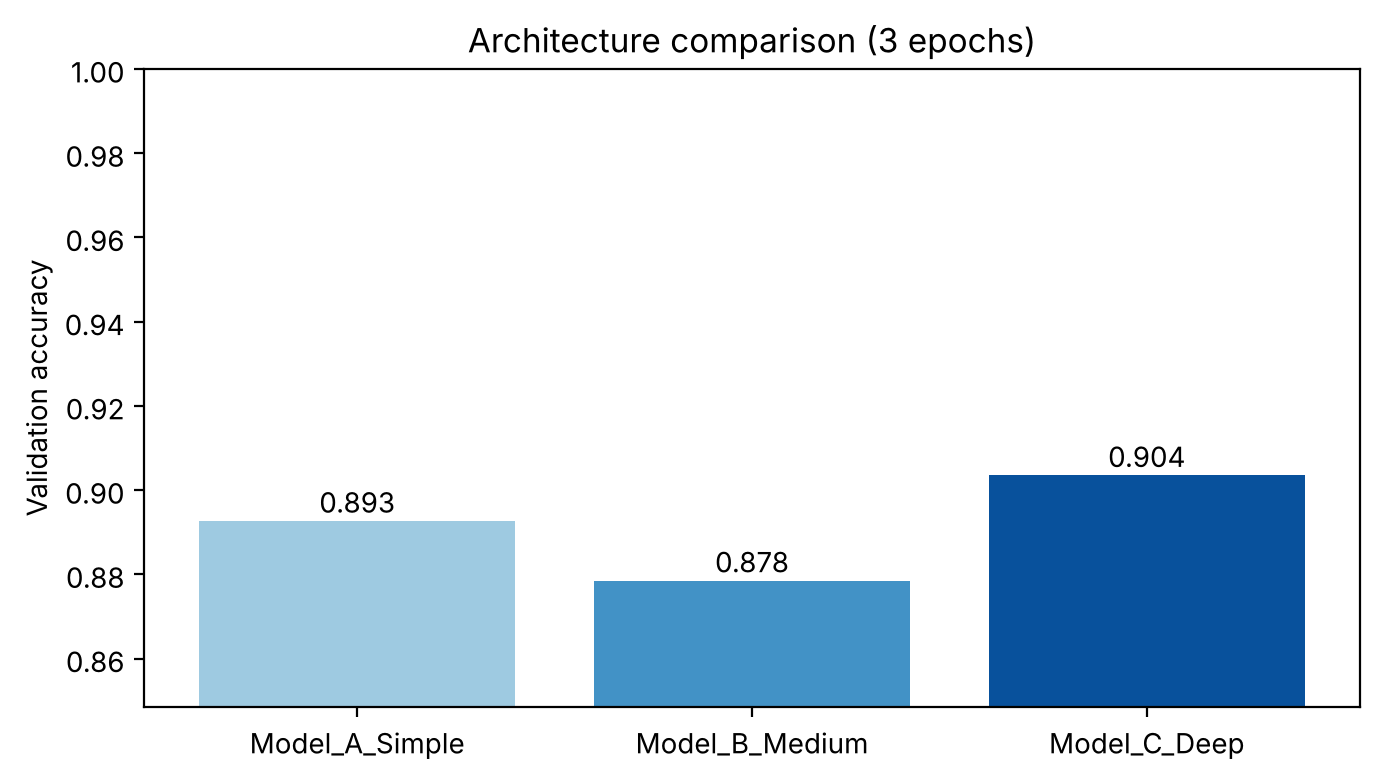

In [9]:
comparison = {}
for builder in [build_model_a, build_model_b, build_model_c]:
    m = builder()
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    t0 = time.time()
    h = m.fit(x_train, y_train, epochs=3, batch_size=128,
              validation_data=(x_val, y_val), verbose=0)
    comparison[m.name] = {
        "params": m.count_params(),
        "val_acc": h.history['val_accuracy'][-1],
        "time_s": time.time() - t0,
    }

print(f"{'Model':18s} {'Params':>10s} {'Val acc':>9s} {'Time (s)':>9s}")
for name, r in comparison.items():
    print(f"{name:18s} {r['params']:>10,d} {r['val_acc']:>9.4f} {r['time_s']:>9.1f}")

plt.figure(figsize=(7, 4))
names = list(comparison.keys())
accs = [comparison[n]['val_acc'] for n in names]
bars = plt.bar(names, accs, color=['#9ecae1', '#4292c6', '#08519c'])
for b, a in zip(bars, accs):
    plt.text(b.get_x() + b.get_width()/2, a + 0.002, f"{a:.3f}", ha='center')
plt.ylim(min(accs) - 0.03, 1.0)
plt.ylabel("Validation accuracy")
plt.title("Architecture comparison (3 epochs)")
plt.tight_layout()
plt.show()

---
# PART 4 — Training & Tuning (Member 4)
**Model C** is trained fully with:
- **Optimizer:** Adam (learning rate 0.001)
- **Loss:** sparse categorical cross-entropy (integer labels, 10 classes)
- **Batch size:** 128
- **EarlyStopping:** stops when validation loss stops improving (patience 3) and restores the best weights → prevents overfitting
- **ReduceLROnPlateau:** halves the learning rate when validation loss plateaus

In [10]:
model = build_model_c()
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1),
]

t0 = time.time()
history = model.fit(x_train, y_train,
                    epochs=20, batch_size=128,
                    validation_data=(x_val, y_val),
                    callbacks=callbacks, verbose=2)
print(f"\nTraining time: {time.time() - t0:.1f} s, epochs run: {len(history.history['loss'])}")

Epoch 1/20


422/422 - 52s - 122ms/step - accuracy: 0.7144 - loss: 0.7705 - val_accuracy: 0.7743 - val_loss: 0.6993 - learning_rate: 0.0010


Epoch 2/20


422/422 - 88s - 208ms/step - accuracy: 0.8210 - loss: 0.4816 - val_accuracy: 0.8860 - val_loss: 0.3139 - learning_rate: 0.0010


Epoch 3/20


422/422 - 76s - 181ms/step - accuracy: 0.8486 - loss: 0.4100 - val_accuracy: 0.8958 - val_loss: 0.2819 - learning_rate: 0.0010


... (29 outputs left out)

422/422 - 57s - 135ms/step - accuracy: 0.9354 - loss: 0.1732 - val_accuracy: 0.9373 - val_loss: 0.1933 - learning_rate: 5.0000e-04


Epoch 18/20


422/422 - 51s - 121ms/step - accuracy: 0.9405 - loss: 0.1591 - val_accuracy: 0.9380 - val_loss: 0.1833 - learning_rate: 2.5000e-04



Training time: 1220.9 s, epochs run: 18


### 4.1 Learning curves
If training accuracy keeps rising while validation accuracy flattens or drops (and validation loss rises), the model is **overfitting**.

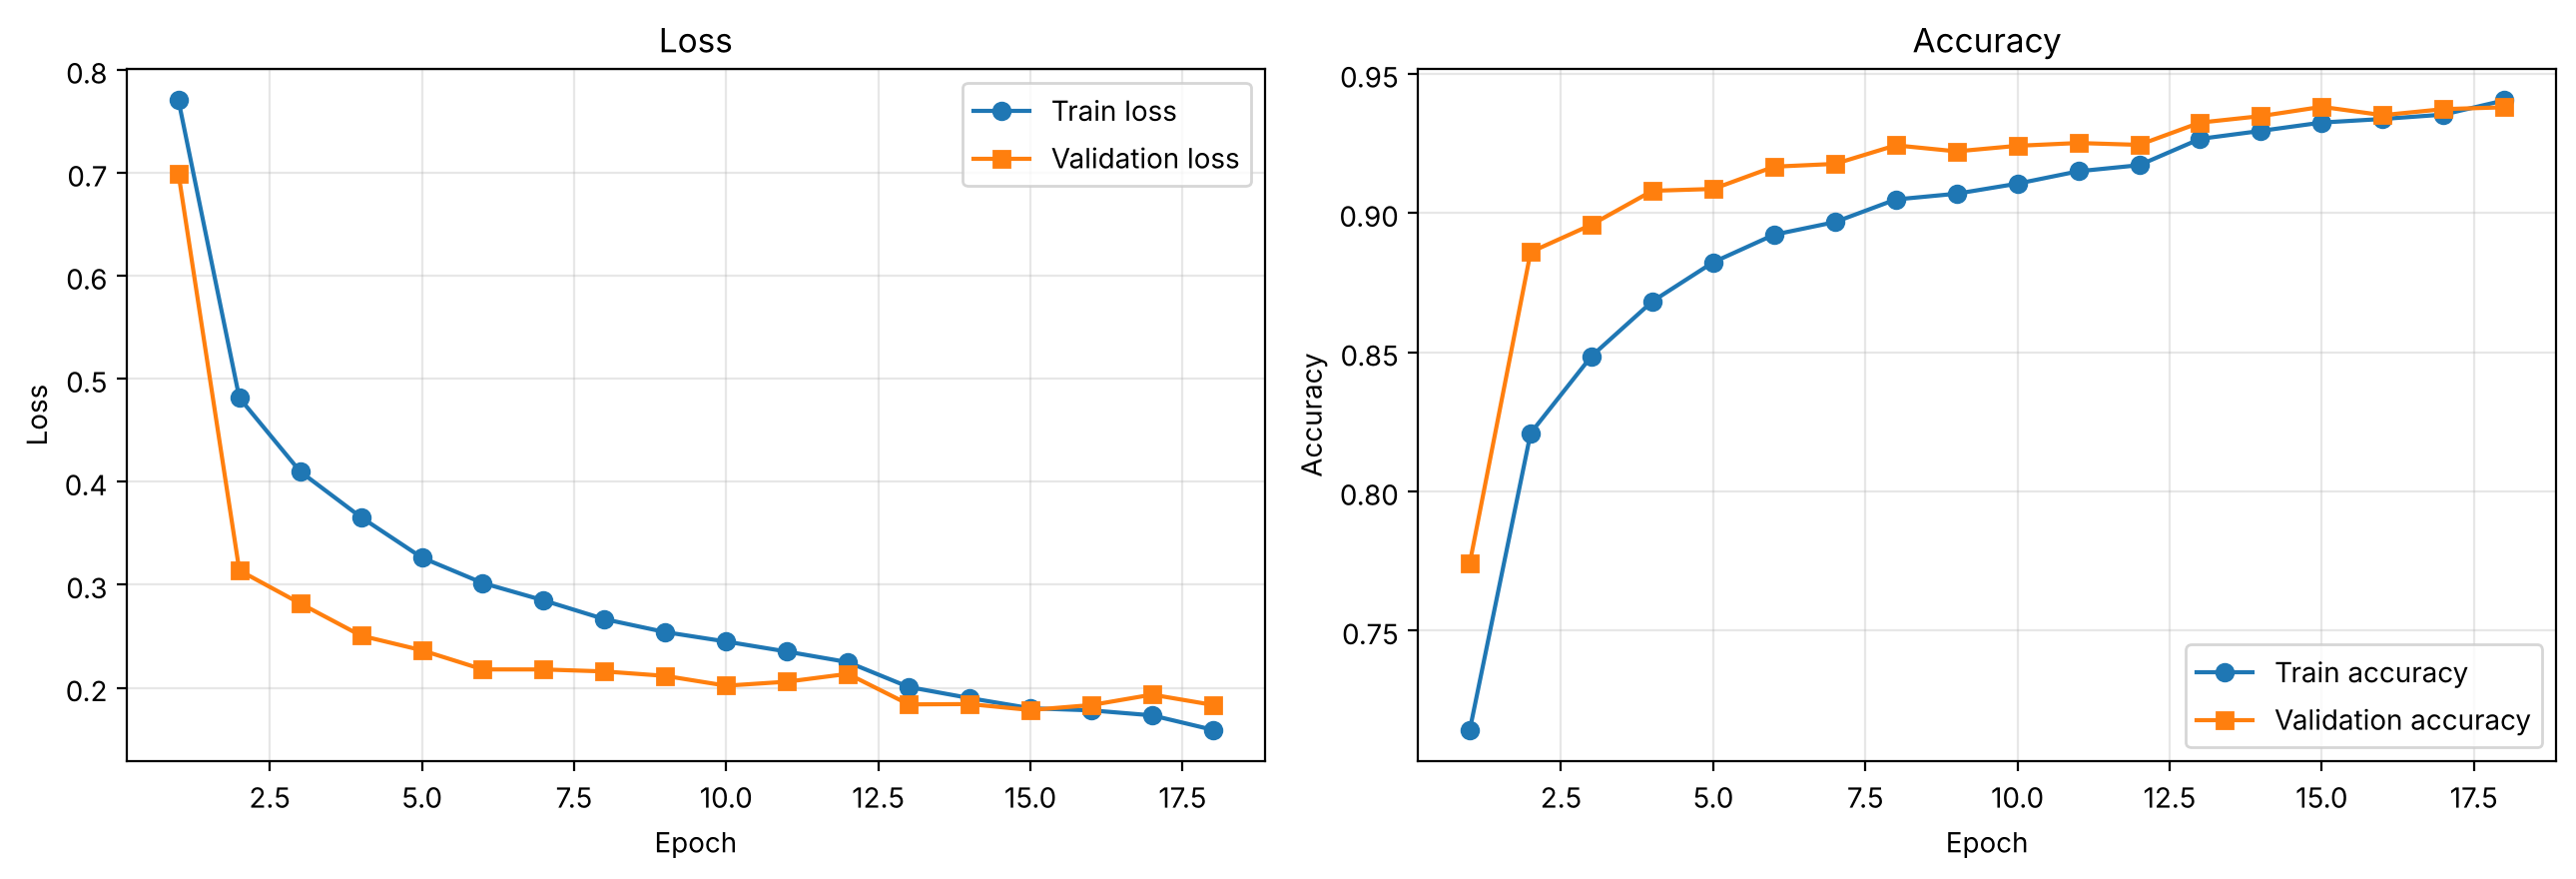

Best epoch: 15 | val_loss = 0.1783 | val_acc = 0.9382


In [11]:
hist = history.history
ep = range(1, len(hist['loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(ep, hist['loss'], 'o-', label='Train loss')
ax[0].plot(ep, hist['val_loss'], 's-', label='Validation loss')
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].set_title("Loss"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(ep, hist['accuracy'], 'o-', label='Train accuracy')
ax[1].plot(ep, hist['val_accuracy'], 's-', label='Validation accuracy')
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].set_title("Accuracy"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

best = int(np.argmin(hist['val_loss']))
print(f"Best epoch: {best+1} | val_loss = {hist['val_loss'][best]:.4f} | val_acc = {hist['val_accuracy'][best]:.4f}")

---
# PART 5 — Evaluation, Error Analysis & Demo (Member 5)
The **test set** has never been seen during training or tuning, so it gives an honest estimate of real performance.

In [12]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss    : {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}  ({test_acc*100:.2f}%)")

y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

Test loss    : 0.2029
Test accuracy: 0.9309  (93.09%)


### 5.1 Precision, recall, F1-score per class
- **Precision:** of all images predicted as class X, how many really are X
- **Recall:** of all real class-X images, how many were found
- **F1:** harmonic mean of precision and recall

In [13]:
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

              precision    recall  f1-score   support

 T-shirt/top     0.8601    0.9100    0.8844      1000
     Trouser     0.9940    0.9920    0.9930      1000
    Pullover     0.8977    0.9130    0.9053      1000
       Dress     0.9340    0.9340    0.9340      1000
        Coat     0.8788    0.8990    0.8888      1000
      Sandal     0.9880    0.9840    0.9860      1000
       Shirt     0.8244    0.7420    0.7811      1000
     Sneaker     0.9608    0.9800    0.9703      1000
         Bag     0.9880    0.9900    0.9890      1000
  Ankle boot     0.9787    0.9650    0.9718      1000

    accuracy                         0.9309     10000
   macro avg     0.9305    0.9309    0.9304     10000
weighted avg     0.9305    0.9309    0.9304     10000



### 5.2 Confusion matrix
Diagonal = correct predictions. Off-diagonal cells show which classes get confused with each other.

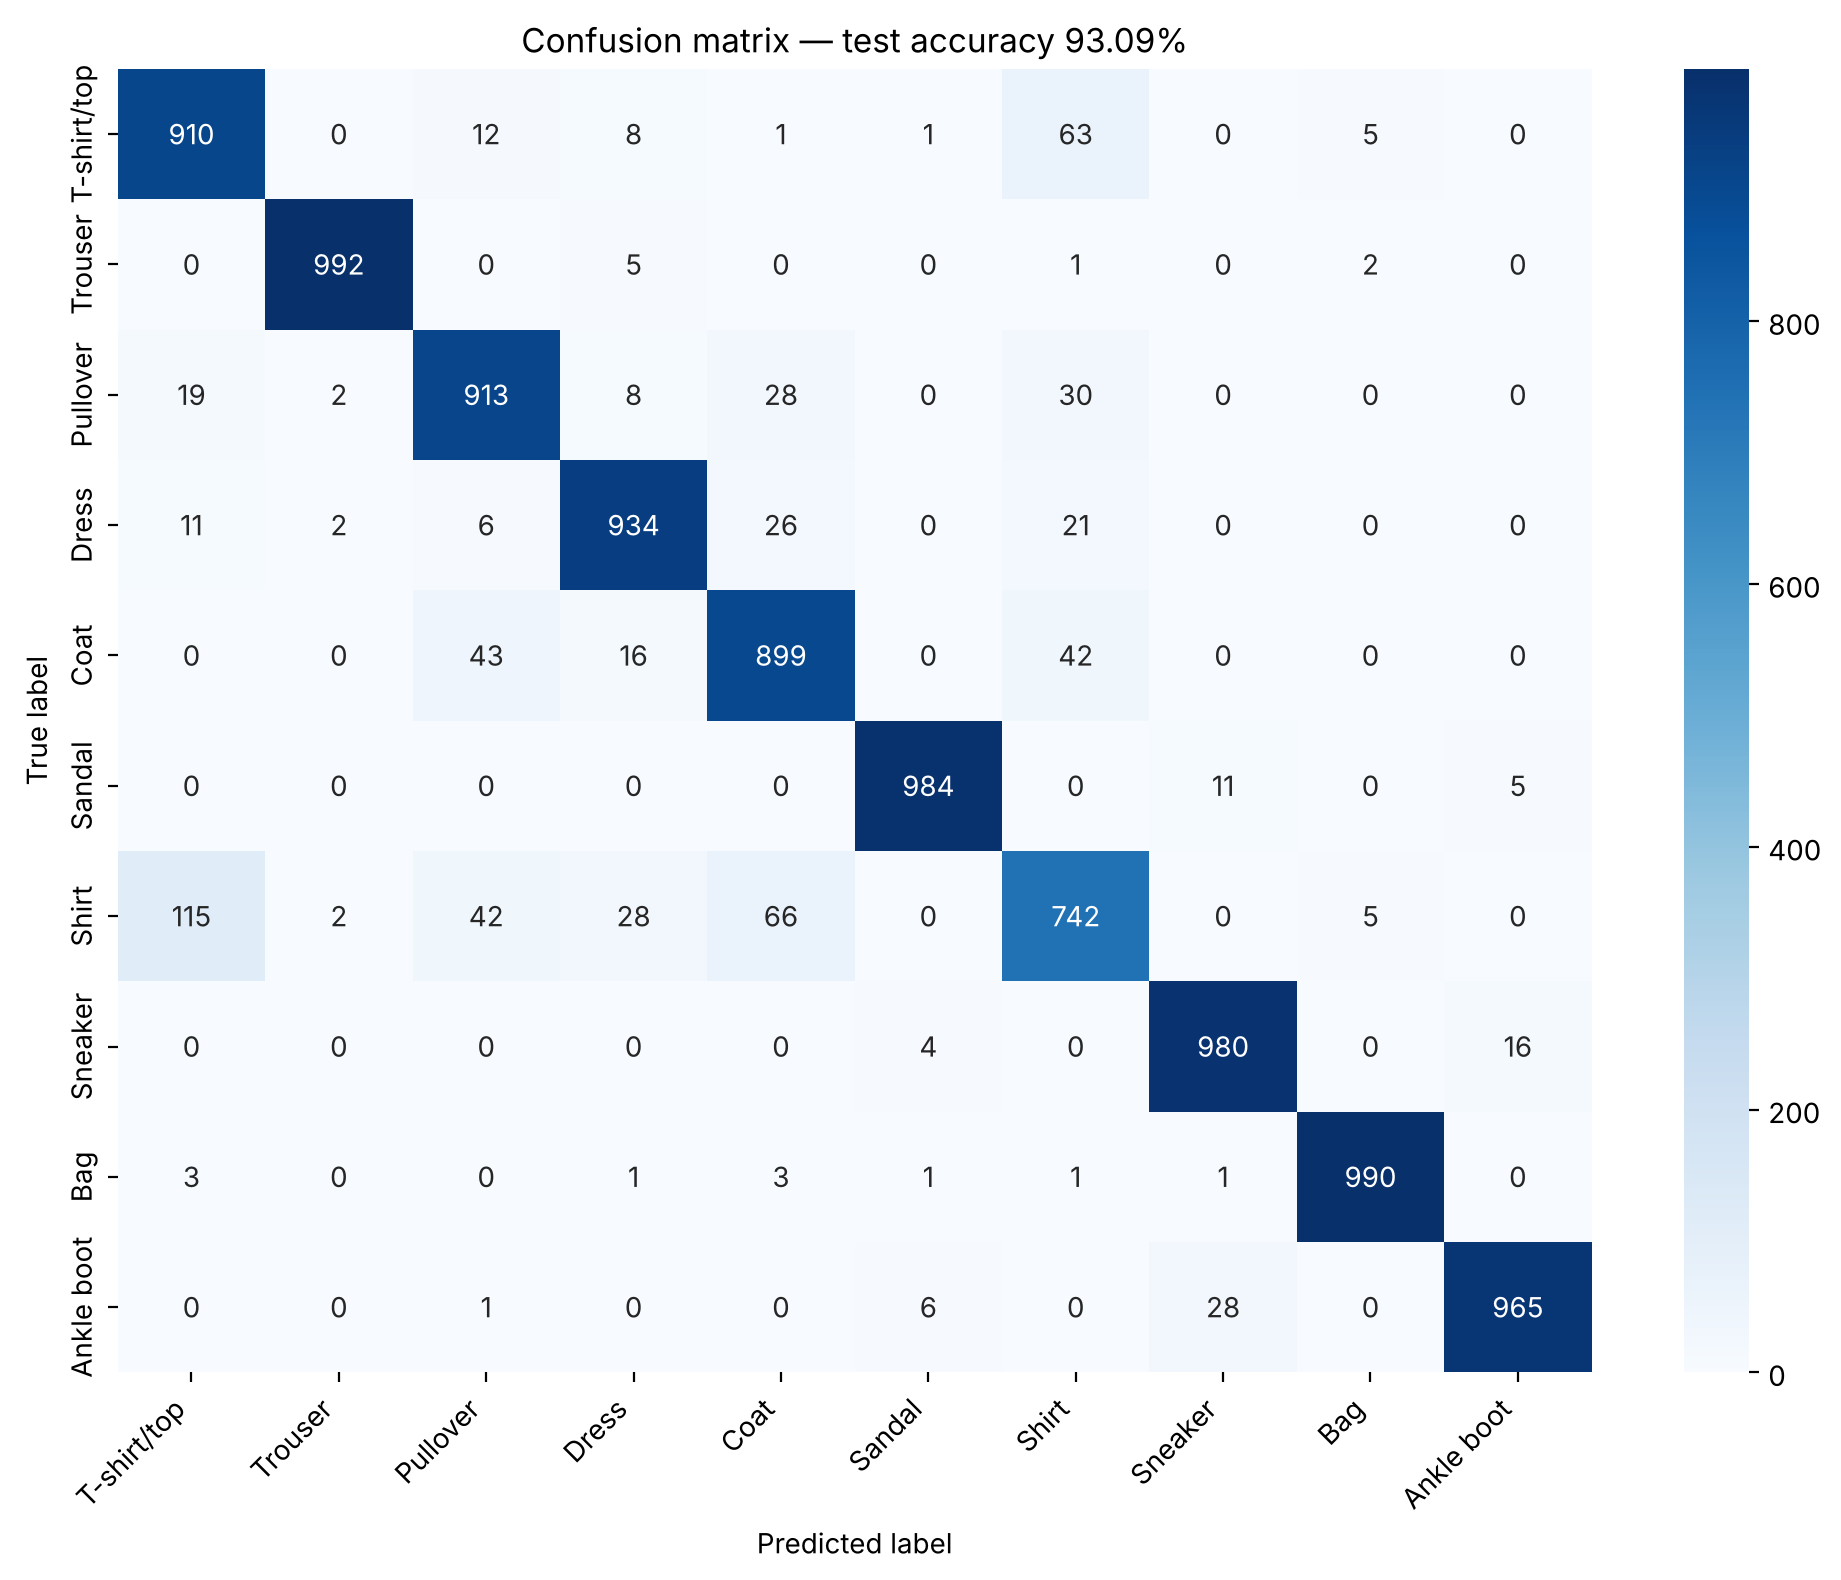

Top 5 confusions (true → predicted):
  Shirt        → T-shirt/top : 115 images
  Shirt        → Coat        : 66 images
  T-shirt/top  → Shirt       : 63 images
  Coat         → Pullover    : 43 images
  Coat         → Shirt       : 42 images


In [14]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted label"); plt.ylabel("True label")
plt.title(f"Confusion matrix — test accuracy {test_acc*100:.2f}%")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Most confused pairs
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
pairs = np.dstack(np.unravel_index(np.argsort(cm_off.ravel())[::-1], cm.shape))[0][:5]
print("Top 5 confusions (true → predicted):")
for t, p in pairs:
    print(f"  {class_names[t]:12s} → {class_names[p]:12s}: {cm_off[t, p]} images")

### 5.3 Misclassified examples

Misclassified: 691 of 10000 test images


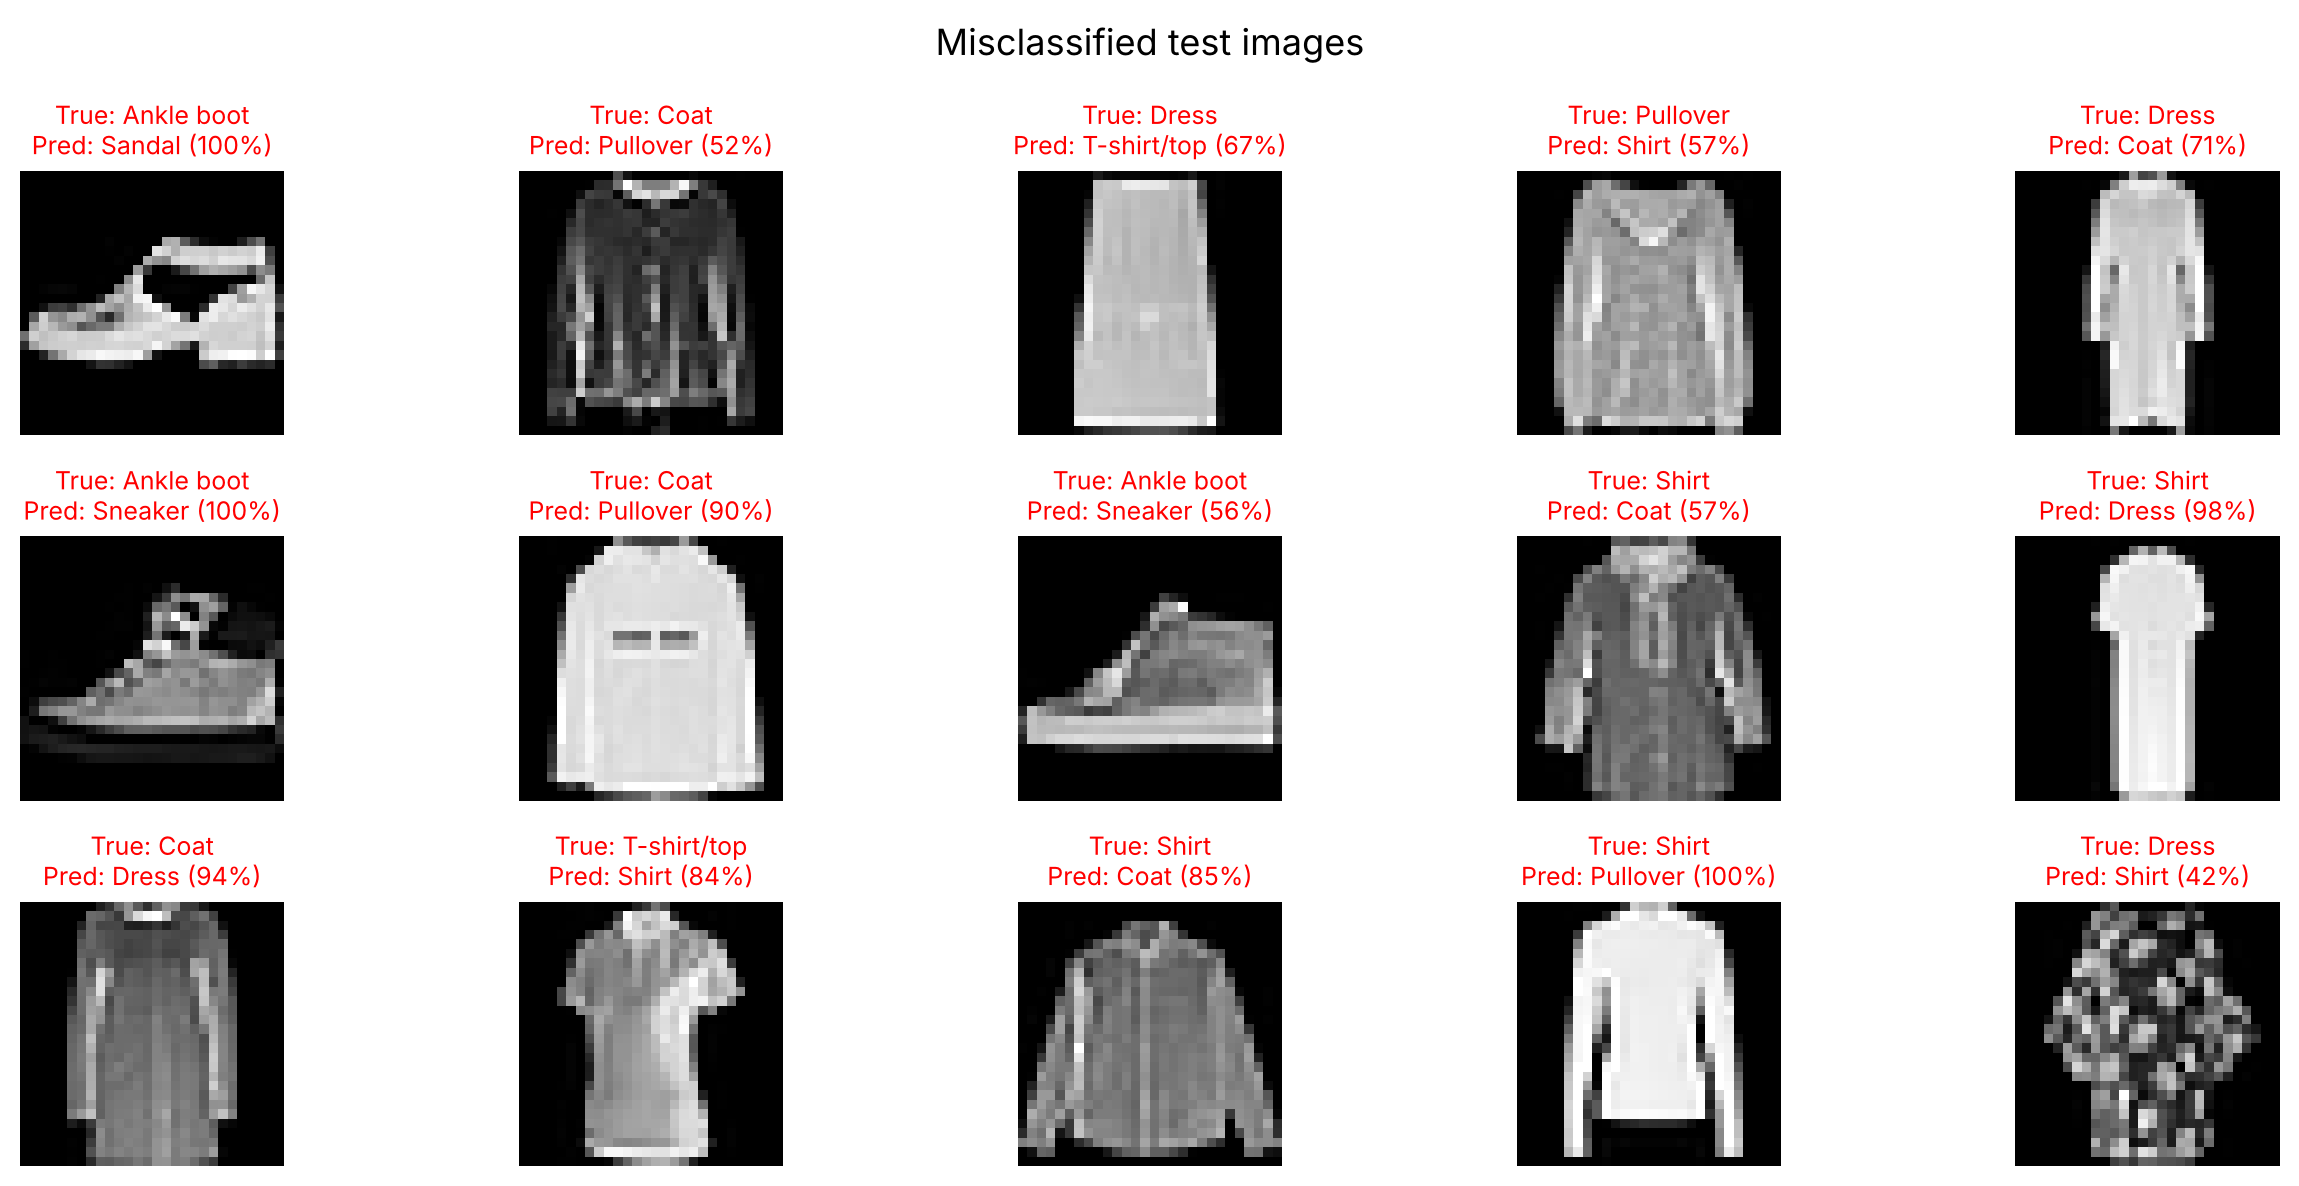

In [15]:
wrong = np.where(y_pred != y_test)[0]
print(f"Misclassified: {len(wrong)} of {len(y_test)} test images")
plt.figure(figsize=(13, 6))
for i, k in enumerate(wrong[:15]):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_test[k, :, :, 0], cmap='gray')
    plt.title(f"True: {class_names[y_test[k]]}\nPred: {class_names[y_pred[k]]} ({y_prob[k].max()*100:.0f}%)",
              fontsize=9, color='red')
    plt.axis('off')
plt.suptitle("Misclassified test images", fontsize=13)
plt.tight_layout()
plt.show()

### 5.4 Demo — prediction with confidence

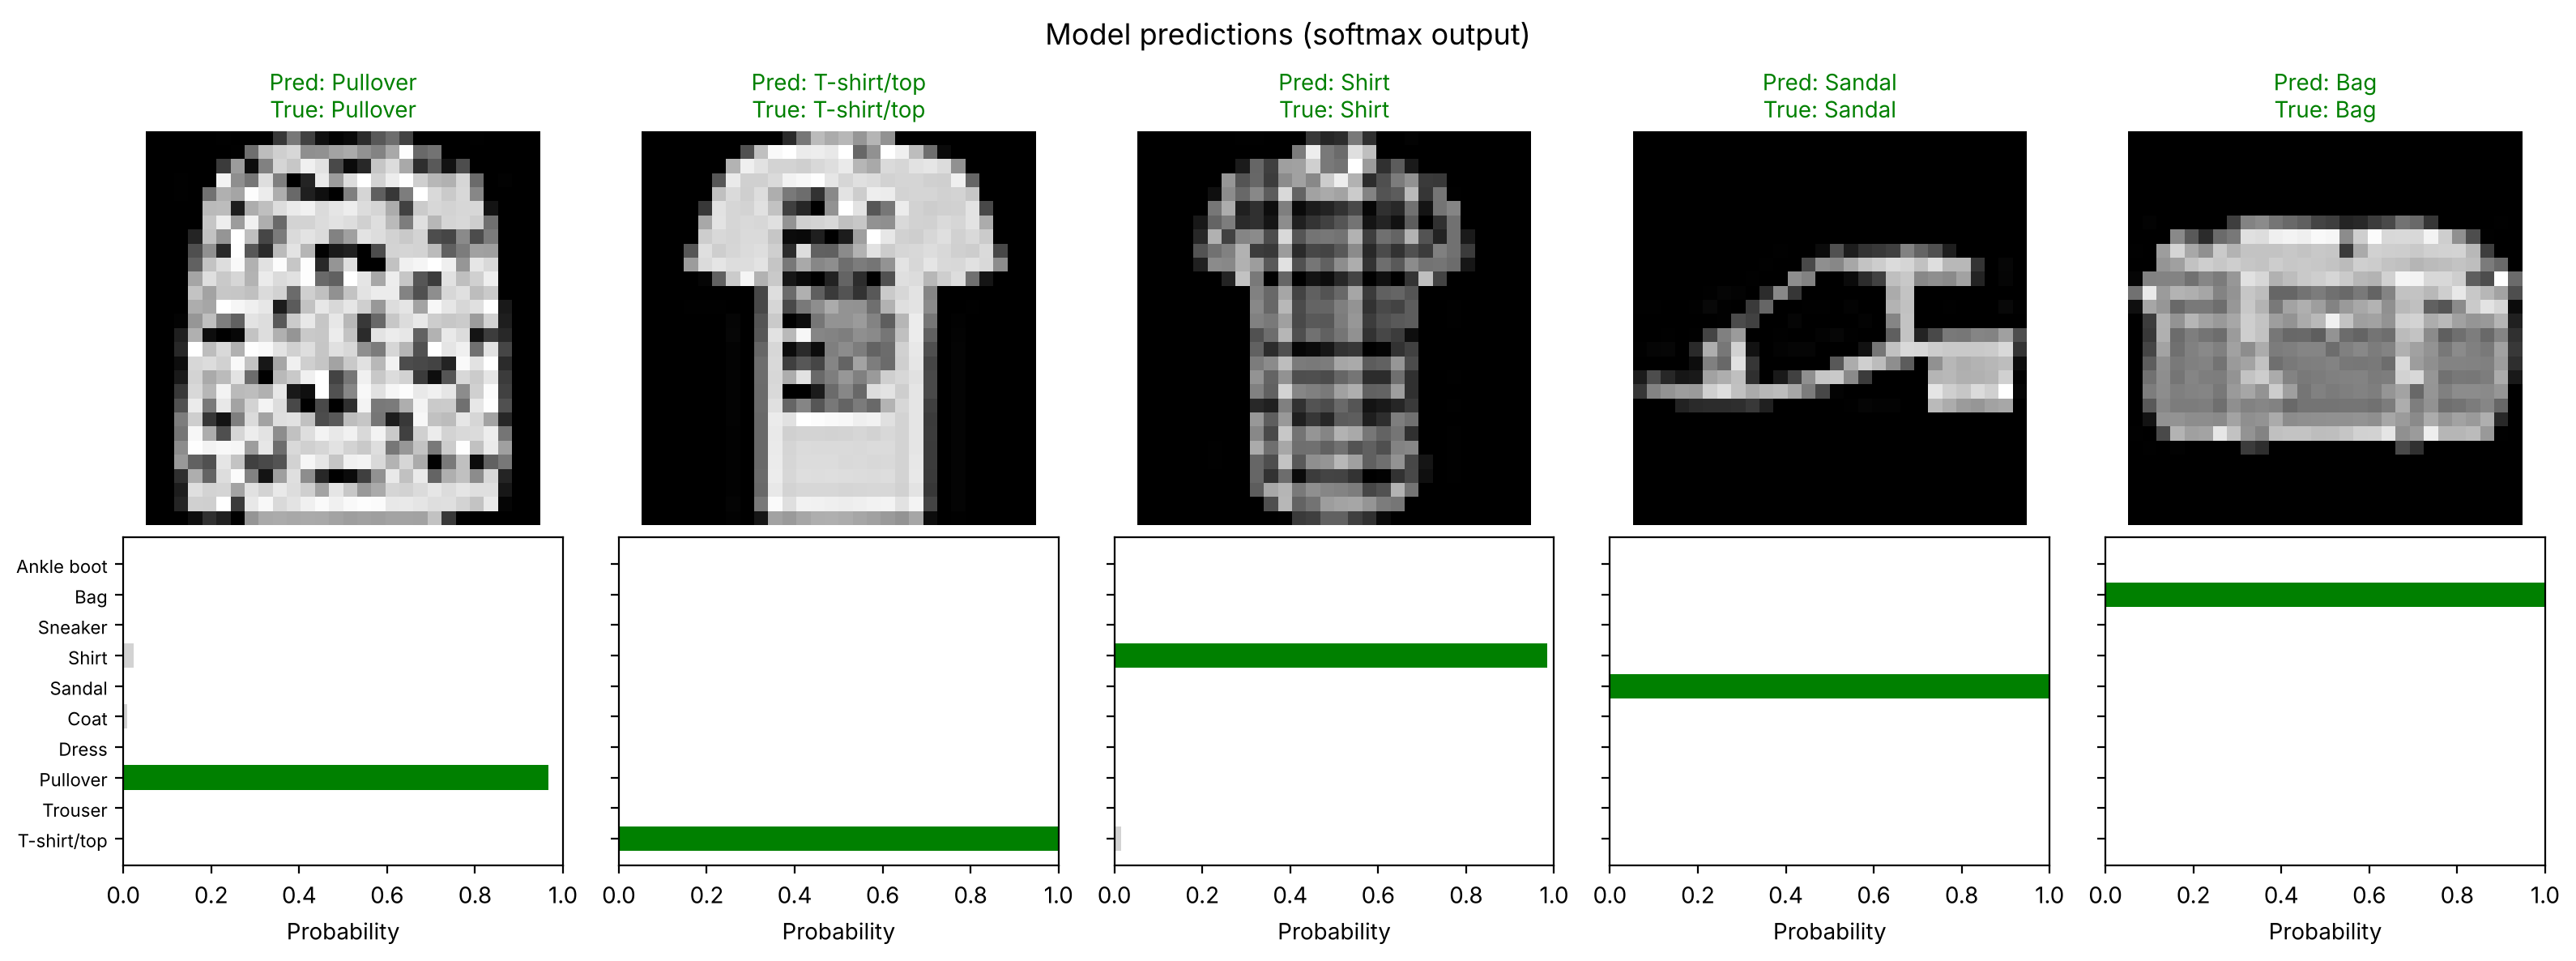

In [16]:
demo_idx = np.random.choice(len(x_test), 5, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(16, 6), gridspec_kw={'height_ratios': [1.2, 1]})
for i, k in enumerate(demo_idx):
    correct = y_pred[k] == y_test[k]
    axes[0, i].imshow(x_test[k, :, :, 0], cmap='gray')
    axes[0, i].set_title(f"Pred: {class_names[y_pred[k]]}\nTrue: {class_names[y_test[k]]}",
                         color='green' if correct else 'red', fontsize=10)
    axes[0, i].axis('off')
    colors = ['green' if j == y_pred[k] else 'lightgray' for j in range(10)]
    axes[1, i].barh(class_names, y_prob[k], color=colors)
    axes[1, i].set_xlim(0, 1)
    axes[1, i].tick_params(axis='y', labelsize=8)
    if i > 0: axes[1, i].set_yticklabels([])
    axes[1, i].set_xlabel("Probability")
plt.suptitle("Model predictions (softmax output)", fontsize=13)
plt.tight_layout()
plt.show()

### 5.5 Learned feature maps
What the trained model's first two convolutional layers "see". Compare with the hand-made filters in Part 2: early layers detect edges, deeper layers respond to more abstract shapes.

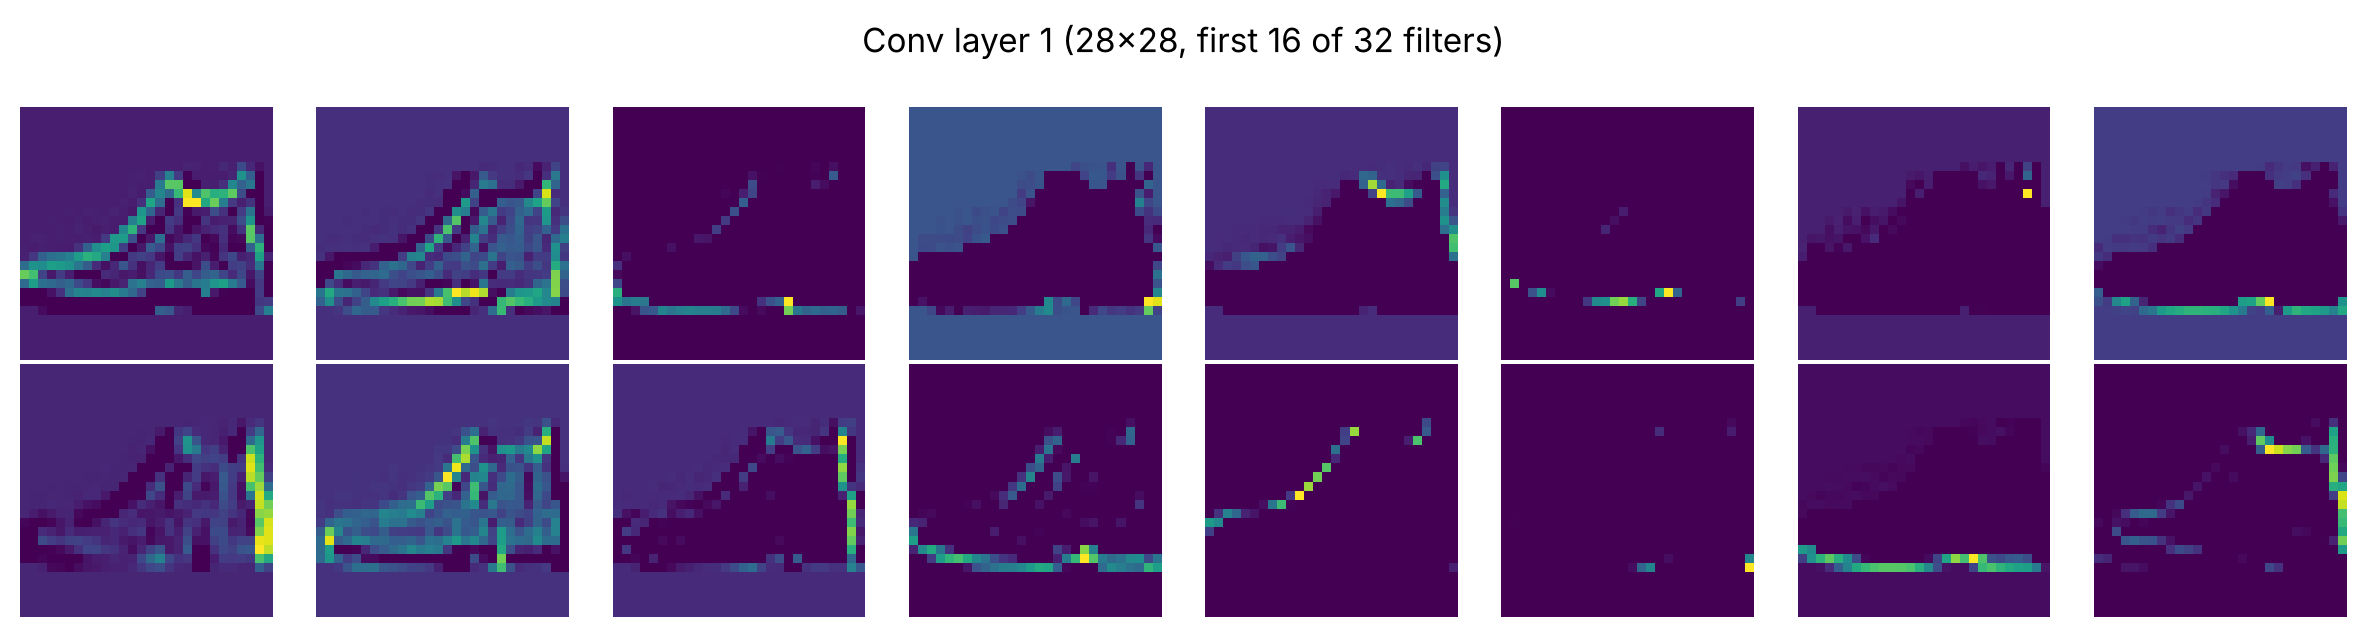

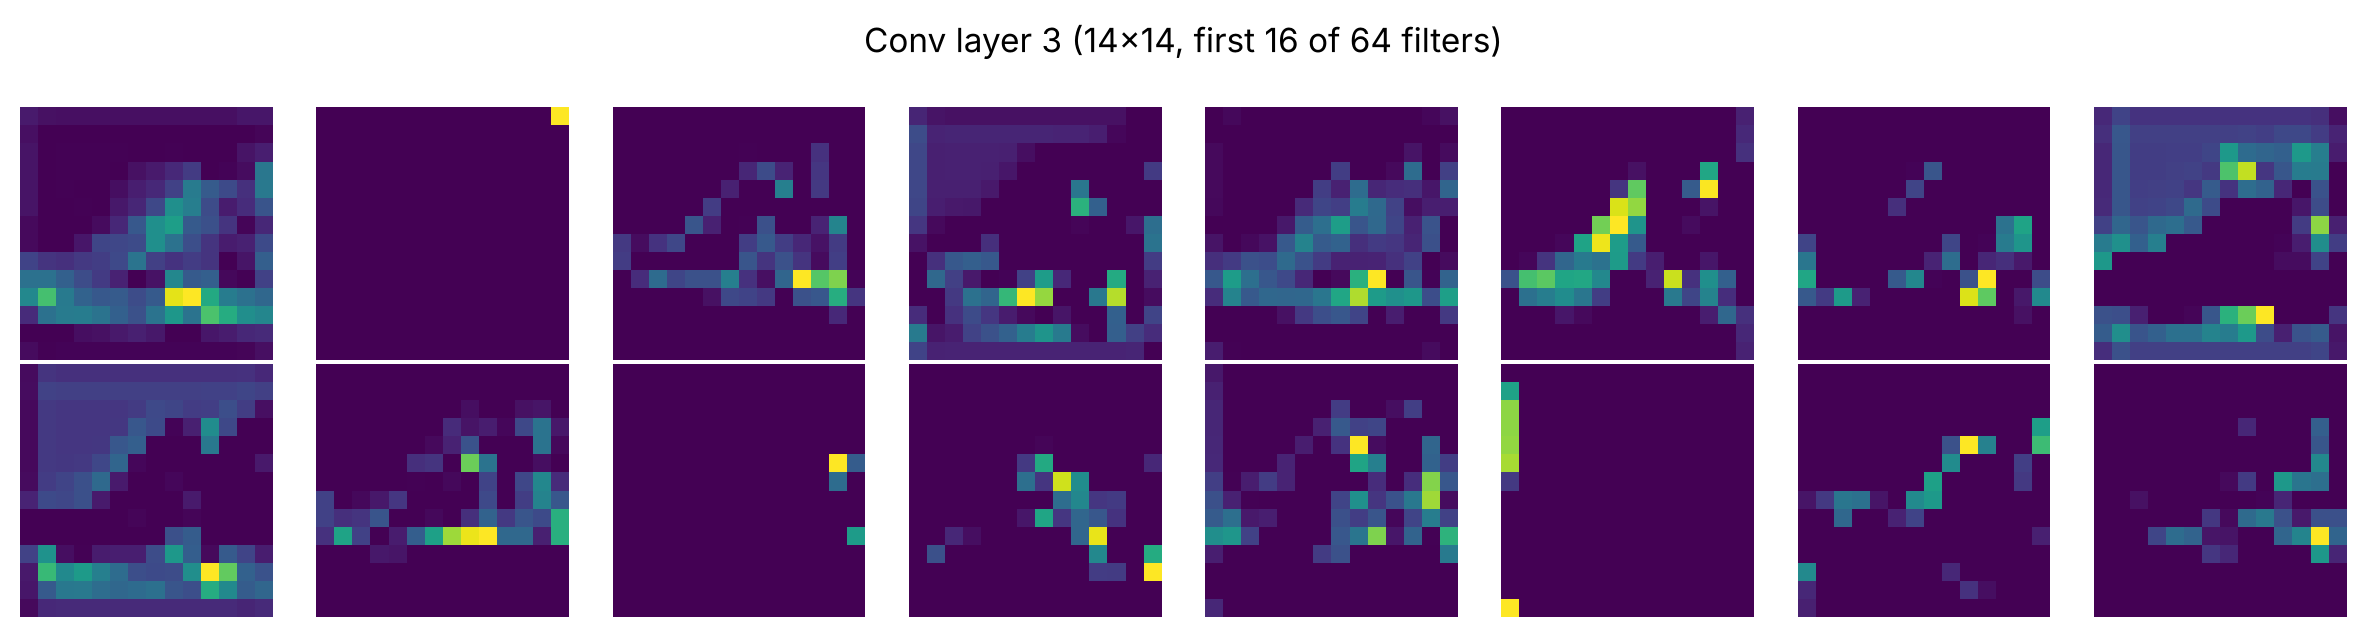

In [17]:
conv_layers = [l for l in model.layers if isinstance(l, layers.Conv2D)]
feature_model = keras.Model(inputs=model.inputs, outputs=[conv_layers[0].output, conv_layers[2].output])
img = x_test[np.where(y_test == 9)[0][0]][np.newaxis]
fm1, fm3 = feature_model.predict(img, verbose=0)

for fm, title in [(fm1, "Conv layer 1 (28×28, first 16 of 32 filters)"),
                  (fm3, "Conv layer 3 (14×14, first 16 of 64 filters)")]:
    plt.figure(figsize=(12, 3.2))
    for i in range(16):
        plt.subplot(2, 8, i + 1)
        plt.imshow(fm[0, :, :, i], cmap='viridis')
        plt.axis('off')
    plt.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()

### 5.6 Save the model

In [18]:
model.save("fashion_mnist_cnn.keras")
print("Saved model to fashion_mnist_cnn.keras")
# To load later: model = keras.models.load_model("fashion_mnist_cnn.keras")

Saved model to fashion_mnist_cnn.keras


---
## Summary
| Item | Value |
|---|---|
| Dataset | Fashion-MNIST (60k train / 10k test, 10 classes) |
| Final model | Model C — 4 Conv2D + BatchNorm + Dropout |
| Optimizer | Adam, lr = 0.001 with ReduceLROnPlateau |
| Regularization | Dropout, BatchNorm, EarlyStopping |

See the printed outputs above for test accuracy, per-class metrics, and the most confused classes.

**Ideas for further experiments:** train with data augmentation (Part 1.4), change filter counts or kernel size, try SGD vs Adam, or apply transfer learning on a custom dataset.